# C02 · Thương mại Việt Nam theo phần và chương HS

**Câu hỏi Q1.** Xuất khẩu và nhập khẩu của Việt Nam thay đổi thế nào theo nhóm sản phẩm ở cấp phần và chương HS?

C02A là biểu đồ bắt buộc, C02B–E bổ trợ. Bộ C02 có 5 biểu đồ, tổng cộng 6 ô vì C02E có 2 ô. Chọn **Run All** để dựng cả bộ. C02A/C dùng Top 5 xuất khẩu, C02B/D dùng Top 5 nhập khẩu riêng.

## C02A · Cơ cấu xuất khẩu theo phần HS

- **Task (Q1.2)** · So sánh cơ cấu xuất khẩu của Việt Nam giữa các phần HS qua 5 mốc 2005, 2010, 2015, 2020 và 2024.
- **Dạng** · Cột chồng 100% (*100% stacked column*). Mỗi năm một cột, mỗi màu đại diện cho một nhóm phần HS.
- **Lý do** · Chuẩn hóa mỗi cột về 100% giúp so tỷ trọng qua các năm có tổng kim ngạch khác nhau. Giữ thứ tự và màu nhóm qua 5 mốc để theo dõi chuyển dịch.
- **Xử lý** · Lọc `Export` ở 5 mốc. Cộng `trade_usd` theo `section_code` để chọn Top 5 **XVI, XI, XII, XX, II**. Giữ tập này qua cả 5 mốc và gộp các phần còn lại vào **Khác**. Tỷ trọng mỗi nhóm bằng kim ngạch nhóm chia cho tổng xuất khẩu cùng năm, nhân 100. Kiểm tra mỗi cột cộng thành 100% trước khi làm tròn.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [ ]:
import sys
from functools import lru_cache
from pathlib import Path

from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "house_style" / "house_style.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


from csv import DictReader
from dataclasses import dataclass
from decimal import Decimal
import re

from notebooks.house_style.house_style import HS_ORDER, OTHER, TRADE_FLOW_ORDER


DATA_DIR = ROOT / "data" / "clean"
YEARS = tuple(range(2005, 2025))
MILESTONES = (2005, 2010, 2015, 2020, 2024)
CHAPTERS = ("84", "85")


@dataclass(frozen=True)
class C02Data:
    groups: tuple[str, ...]
    sections: dict[tuple[int, str, str], Decimal]
    products: dict[tuple[int, str, str], Decimal]
    totals: dict[tuple[int, str], Decimal]
    import_groups: tuple[str, ...]
    import_sections: dict[tuple[int, str, str], Decimal]

    def share(self, year, flow, group):
        values = self.import_sections if flow == "Import" else self.sections
        return values[year, flow, group] / self.totals[year, flow]


def read_values(path, code_field, *, extra_fields=()):
    values = {}
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = DictReader(stream)
        fields = {"year", "trade_flow", code_field, "trade_usd", *extra_fields}
        if missing := fields.difference(reader.fieldnames or ()):
            raise ValueError(f"{path.name}: thiếu cột {sorted(missing)}")
        for row in reader:
            line = reader.line_num
            try:
                if any(not (row[field] or "").strip() for field in fields):
                    raise ValueError("thiếu giá trị")
                year = int(row["year"])
                flow, code = row["trade_flow"], row[code_field]
                amount = Decimal(row["trade_usd"])
                if flow not in TRADE_FLOW_ORDER or not amount.is_finite() or amount < 0:
                    raise ValueError("chiều thương mại hoặc kim ngạch không hợp lệ")
                if code_field == "hs2" and not re.fullmatch(r"[0-9]{2}", code):
                    raise ValueError("hs2 phải có hai ký tự số")
                if code_field == "section_code" and code not in HS_ORDER[:-1]:
                    raise ValueError("mã phần HS không hợp lệ")
                if year not in YEARS:
                    continue
                key = (year, flow, code)
                if key in values:
                    raise ValueError(f"trùng khóa {key}")
                values[key] = amount
            except (ValueError, ArithmeticError) as error:
                raise ValueError(f"{path.name}:{line}: {error}") from error
    return values


def require_coverage(values, codes, filename):
    for year in YEARS:
        for flow in TRADE_FLOW_ORDER:
            for code in codes:
                if (year, flow, code) not in values:
                    raise ValueError(f"{filename}: thiếu {(year, flow, code)}")


def group_sections(raw, rank_flow, flows):
    codes = [code for code in HS_ORDER if code != OTHER]
    require_coverage(raw, codes, "section_year.csv")
    # Stable ties follow the shared HS order.
    top = sorted(codes, key=lambda code: -sum(raw[y, rank_flow, code] for y in MILESTONES))[:5]
    groups = (*top, OTHER)
    others = [code for code in codes if code not in top]
    totals = {}
    grouped = {}
    for year in YEARS:
        for flow in flows:
            key = (year, flow)
            total = sum(raw[year, flow, code] for code in codes)
            totals[key] = total
            for code in top:
                grouped[year, flow, code] = raw[year, flow, code]
            grouped[year, flow, OTHER] = sum(raw[year, flow, code] for code in others)
            if total <= 0 or sum(grouped[year, flow, code] for code in groups) != total:
                raise ValueError(f"Tổng phần HS không hợp lệ sau khi gộp: {key}")
    return groups, grouped, totals


def load_data(data_dir=DATA_DIR):
    """Check the input schema and return exact USD values, shared groups and totals."""
    data_dir = Path(data_dir)
    sections = read_values(data_dir / "section_year.csv", "section_code", extra_fields=("section_name",))
    products = read_values(data_dir / "product_year.csv", "hs2")
    require_coverage(products, sorted({key[2] for key in products} | set(CHAPTERS)), "product_year.csv")
    groups, grouped, totals = group_sections(sections, 'Export', TRADE_FLOW_ORDER)
    import_groups, import_sections, _ = group_sections(sections, 'Import', ('Import',))
    for year, flow in totals:
        if sum(amount for (y, f, _), amount in products.items() if (y, f) == (year, flow)) != totals[year, flow]:
            raise ValueError(f"Tổng kim ngạch theo chương và phần lệch nhau: {(year, flow)}")
    return C02Data(groups, grouped, products, totals, import_groups, import_sections)


@lru_cache(maxsize=1)
def tai_du_lieu(data_dir):
    """Đọc và kiểm tra hai bảng BACI một lần cho cả notebook."""
    return load_data(data_dir)


def xu_ly_c02a(data_dir):
    """Chuẩn bị Top 5 xuất khẩu và tỷ trọng từng nhóm tại 5 mốc."""
    data = tai_du_lieu(data_dir)
    groups = data.groups
    shares = {year: tuple(data.share(year, "Export", group) for group in groups)
              for year in MILESTONES}
    return data, groups, shares

In [2]:
from matplotlib import rc_context, rcParams
from matplotlib.colors import to_rgb
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator

from notebooks.house_style.house_style import (
    BAR_WIDTH, COUNTRY_COLORS, DIRECT_LABEL, HS_COLORS, HS_LABELS, SOURCE, SUBTITLE,
    TRADE_FLOW_COLORS, TRADE_FLOW_LABELS, TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS,
    TRADE_FLOW_ORDER, apply_style, format_number, format_percent, format_year, grayscale,
)


# Redundant symbols distinguish HS lines and stack segments independently of colour.
HS_MARKS = ("o", "s", "^", "D", "P", "x")
HS_HATCHES = ("/", chr(92), "x", ".", "-", "")


def heading(fig, title, scope, source):
    fig.suptitle(title, y=.98)
    fig.text(.5, .925, "Việt Nam · " + scope, va="top", **{**SUBTITLE, "color": COUNTRY_COLORS["VNM"]})
    fig.text(.5, .027, f"Nguồn · CEPII BACI HS2002 V202601 · {source}", **SOURCE)


def add_table(ax, headings, rows):
    ax.set_axis_off()
    table = ax.table(cellText=rows, colLabels=headings, cellLoc="center", bbox=(0, 0, 1, 1))
    table.auto_set_font_size(False)
    table.set_fontsize(rcParams["legend.fontsize"])
    for (row, _), cell in table.get_celld().items():
        cell.set_edgecolor(rcParams["axes.edgecolor"])
        cell.set_linewidth(rcParams["axes.linewidth"] / 2)
        if row == 0:
            cell.get_text().set_weight(rcParams["figure.titleweight"])


def section_heading(code):
    return HS_LABELS[code].split(" · ")[0]


def legend_above(ax):
    ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(.5, 1.01))


def composition(data, flow, title):
    fig = Figure(figsize=(11, 7))
    ax, table = fig.subplots(2, gridspec_kw={"height_ratios": (3, 1.5)})
    fig.subplots_adjust(left=.09, right=.94, bottom=.09, top=.79, hspace=.44)
    heading(fig, title, "5 mốc năm từ 2005 đến 2024", "section_year.csv")
    groups = data.import_groups if flow == "Import" else data.groups
    positions = list(range(len(MILESTONES)))
    bottoms = [0.] * len(positions)
    for group, hatch in zip(groups, HS_HATCHES):
        color = HS_COLORS[group]
        dark = float(grayscale(to_rgb(color))[0]) < .55
        ink = rcParams["axes.facecolor"] if dark else rcParams["text.color"]
        shares = [float(data.share(year, flow, group)) for year in MILESTONES]
        ax.bar(positions, shares, bottom=bottoms, width=BAR_WIDTH, color=color,
               edgecolor=ink, linewidth=0, hatch=hatch, label=HS_LABELS[group])
        for x, bottom, share in zip(positions, bottoms, shares):
            if share >= .085:
                ax.text(x, bottom + share / 2, format_percent(share),
                        ha="center", va="center", color=ink,
                        bbox={"facecolor": color, "edgecolor": "none", "pad": 1}, **DIRECT_LABEL)
        bottoms = [bottom + share for bottom, share in zip(bottoms, shares)]
    ax.set(ylim=(0, 1), xlabel="Năm", ylabel=f"Tỷ trọng {TRADE_FLOW_LABELS[flow].lower()} (%)")
    ax.set_xticks(positions, [format_year(year) for year in MILESTONES])
    ax.yaxis.set_major_locator(MultipleLocator(.25))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_percent(value, 0)))
    legend_above(ax)
    rows = [[section_heading(code), *[format_percent(float(data.share(y, flow, code))) for y in MILESTONES]]
            for code in groups]
    add_table(table, ["Phần HS", *map(format_year, MILESTONES)], rows)
    return fig


def plot_c02a(data):
    """Return the 100% stacked export composition figure."""
    with apply_style():
        return composition(data, "Export", "C02A · Cơ cấu xuất khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XI, XII, XX, II, Other
Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.
Đã lưu: outputs\core_charts\C02\C02A.png và outputs\core_charts\C02\C02A.svg


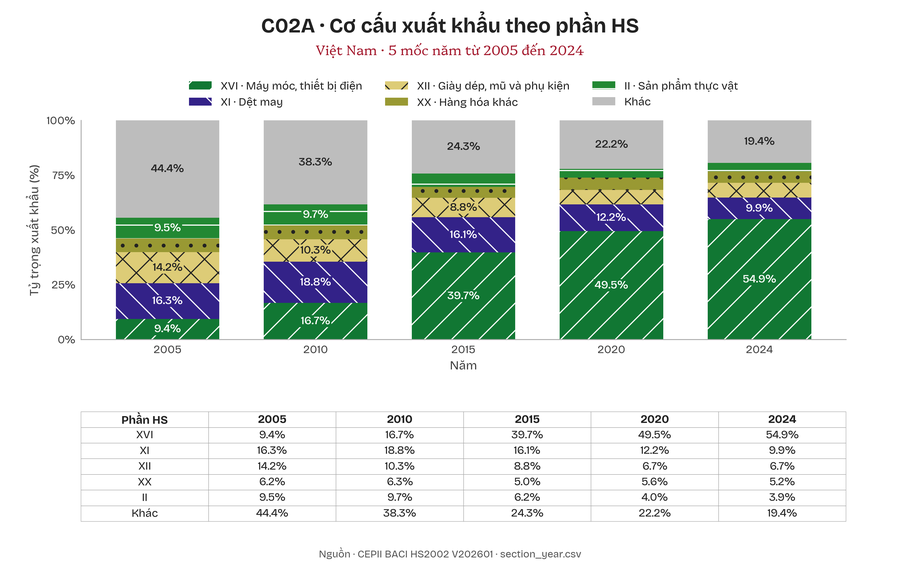

In [3]:
OUTPUT_DIR = ROOT / "outputs" / "core_charts" / "C02"


def save_figure(fig, name, output_dir=OUTPUT_DIR):
    """Save PNG and SVG using the shared export theme and return their paths."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    paths = tuple(output_dir / f"{name}.{extension}" for extension in ("png", "svg"))
    with apply_style(), rc_context({"svg.fonttype": "path"}):
        for path in paths:
            fig.savefig(path)
    return paths


MA_BIEU_DO = "C02A"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, shares = xu_ly_c02a(DU_LIEU)
fig = plot_c02a(data)
assert len(groups) == 6
assert all(abs(sum(shares[year]) - 1) < 1e-12 for year in MILESTONES)
for i, bars in enumerate(fig.axes[0].containers):
    expected = tuple(float(shares[year][i]) for year in MILESTONES)
    assert all(abs(bar.get_height() - share) < 1e-12
               for bar, share in zip(bars, expected, strict=True))
assert len(fig.axes[0].containers) == len(groups)
print("Nhóm theo thứ tự:", ", ".join(groups))
print("Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02A

Phần XVI tăng từ **9.4%** năm 2005 lên **54.9%** năm 2024. Tỷ trọng nhóm Khác giảm từ **44.4%** xuống **19.4%**. Các tỷ trọng dùng tổng xuất khẩu của từng năm.

## C02B · Cơ cấu nhập khẩu theo phần HS

- **Task (Q1.2 mở rộng)** · So sánh cơ cấu nhập khẩu của Việt Nam giữa các phần HS qua 5 mốc 2005, 2010, 2015, 2020 và 2024.
- **Dạng** · Cột chồng 100% (*100% stacked column*), cùng quy cách trục và cách mã hóa màu theo phần HS như C02A.
- **Lý do** · Các cột cùng cao 100% giúp đọc trực tiếp mức thay đổi tỷ trọng của các nhóm nhập khẩu. Những phần xuất hiện trên cả C02A và C02B giữ cùng màu.
- **Xử lý** · Lọc `Import` ở 5 mốc và chọn Top 5 theo tổng nhập khẩu **XVI, XV, XI, VI, VII**. Gộp các phần còn lại vào **Khác**. Chia kim ngạch mỗi nhóm cho tổng nhập khẩu cùng năm, nhân 100. Kiểm tra mỗi cột cộng thành 100% trước khi làm tròn.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [4]:
def xu_ly_c02b(data_dir):
    """Chuẩn bị Top 5 nhập khẩu và tỷ trọng từng nhóm tại 5 mốc."""
    data = tai_du_lieu(data_dir)
    groups = data.import_groups
    shares = {year: tuple(data.share(year, "Import", group) for group in groups)
              for year in MILESTONES}
    return data, groups, shares

In [5]:
def plot_c02b(data):
    """Return the 100% stacked import composition figure."""
    with apply_style():
        return composition(data, "Import", "C02B · Cơ cấu nhập khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XV, XI, VI, VII, Other
Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.
Đã lưu: outputs\core_charts\C02\C02B.png và outputs\core_charts\C02\C02B.svg


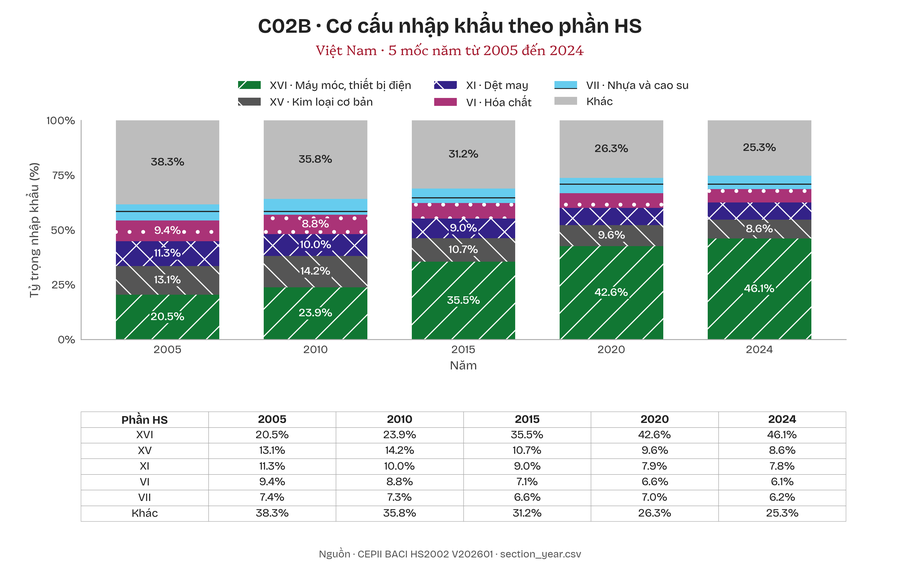

In [6]:
MA_BIEU_DO = "C02B"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, shares = xu_ly_c02b(DU_LIEU)
fig = plot_c02b(data)
assert len(groups) == 6
assert all(abs(sum(shares[year]) - 1) < 1e-12 for year in MILESTONES)
for i, bars in enumerate(fig.axes[0].containers):
    expected = tuple(float(shares[year][i]) for year in MILESTONES)
    assert all(abs(bar.get_height() - share) < 1e-12
               for bar, share in zip(bars, expected, strict=True))
assert len(fig.axes[0].containers) == len(groups)
print("Nhóm theo thứ tự:", ", ".join(groups))
print("Đã kiểm tra 5/5 cột có tổng tỷ trọng 100%.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02B

Phần XVI tăng từ **20.5%** lên **46.1%** nhập khẩu. Nhóm Khác giảm từ **38.3%** xuống **25.3%**. Nhóm Khác của nhập khẩu được xác định theo Top 5 nhập khẩu.

## C02C · Kim ngạch xuất khẩu theo phần HS

- **Task (Q1.2 bổ trợ)** · Phân tích xu hướng kim ngạch xuất khẩu của từng nhóm phần HS trong giai đoạn 2005–2024.
- **Dạng** · Biểu đồ nhiều đường (*multi-line chart*). Một ô có 6 đường, tương ứng Top 5 xuất khẩu và **Khác**.
- **Lý do** · Kim ngạch tuyệt đối giúp nhận ra nhóm có giá trị xuất khẩu tăng dù tỷ trọng giảm. C02C và C02D dùng chung thang dọc để so trực tiếp quy mô.
- **Xử lý** · Lọc `Export` cho đủ 20 năm và giữ Top 5 từ C02A. Gộp các phần còn lại theo từng năm, kiểm tra tổng trước và sau khi gộp, rồi chia kim ngạch USD cho 1 tỷ để vẽ.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [7]:
def xu_ly_c02c(data_dir):
    """Lấy chuỗi tỷ USD theo từng nhóm và giữ số USD để đối chiếu tổng."""
    data = tai_du_lieu(data_dir)
    groups, values = data.groups, data.sections
    usd = tuple(tuple(values[year, "Export", group] for year in YEARS) for group in groups)
    return data, groups, usd

In [8]:
def format_value(usd):
    return format_number(float(usd / 1_000_000_000), 1)


def value_axis(ax, limit, ylabel):
    ax.set(xlim=(YEARS[0], YEARS[-1]), ylim=(0, limit), xlabel="Năm", ylabel=ylabel)
    ax.set_xticks(MILESTONES, [format_year(year) for year in MILESTONES])
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_number(value)))


def section_trends(data, flow, title):
    fig = Figure(figsize=(11, 10))
    ax, table = fig.subplots(2, gridspec_kw={"height_ratios": (3, 3.7)})
    fig.subplots_adjust(left=.09, right=.94, bottom=.075, top=.83, hspace=.31)
    heading(fig, title, "2005–2024", "section_year.csv")
    groups, values = (data.groups, data.sections) if flow == "Export" else (data.import_groups, data.import_sections)
    export_peak = max(v for (_, direction, _), v in data.sections.items() if direction == "Export")
    limit = float(max(export_peak, max(data.import_sections.values())) / 1_000_000_000) * 1.08
    for group, marker in zip(groups, HS_MARKS):
        ax.plot(YEARS, [float(values[y, flow, group] / 1_000_000_000) for y in YEARS],
                color=HS_COLORS[group], marker=marker, label=HS_LABELS[group])
    value_axis(ax, limit, f"{TRADE_FLOW_LABELS[flow]} (tỷ USD)")
    legend_above(ax)
    rows = [[format_year(y), *[format_value(values[y, flow, code]) for code in groups]] for y in YEARS]
    add_table(table, ["Năm", *map(section_heading, groups)], rows)
    return fig


def plot_c02c(data):
    """Return the six-series export figure."""
    with apply_style():
        return section_trends(data, "Export", "C02C · Kim ngạch xuất khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XI, XII, XX, II, Other
Đã kiểm tra 120 điểm và 20/20 tổng năm từ 2005 đến 2024.
Đã lưu: outputs\core_charts\C02\C02C.png và outputs\core_charts\C02\C02C.svg


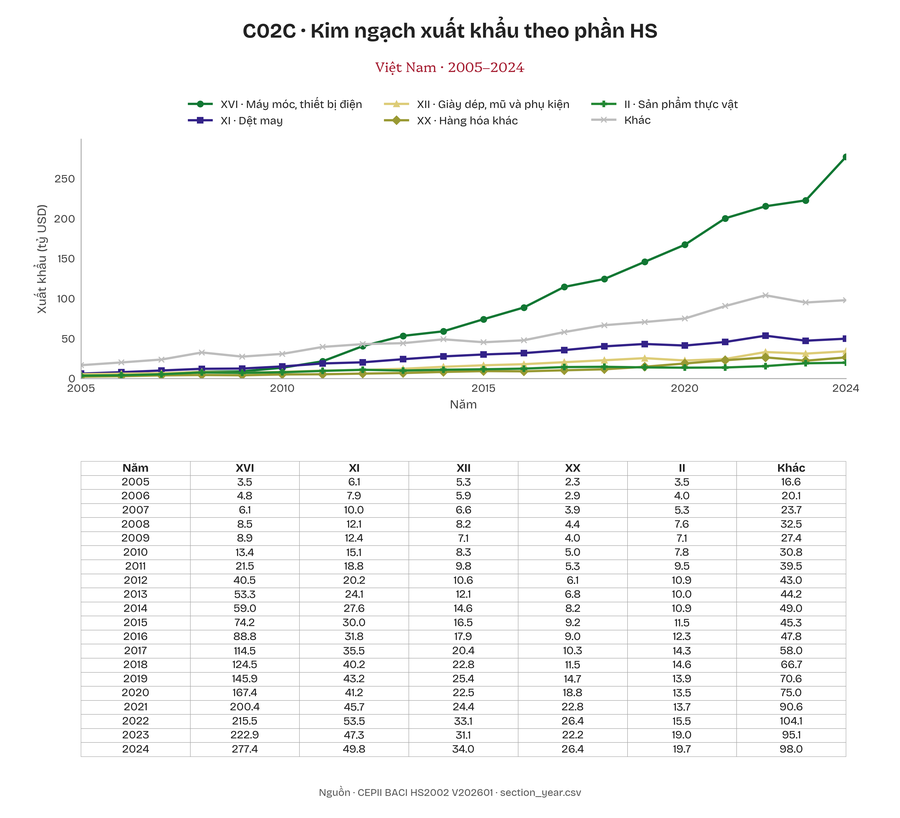

In [9]:
def kiem_tra_duong(ax, chuoi):
    """Đối chiếu từng điểm trên Figure với chuỗi tỷ USD đã xử lý."""
    for line, expected in zip(ax.lines, chuoi, strict=True):
        assert tuple(line.get_xdata()) == YEARS
        assert tuple(line.get_ydata()) == expected


MA_BIEU_DO = "C02C"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, usd = xu_ly_c02c(DU_LIEU)
fig = plot_c02c(data)
assert len(groups) == 6
assert all(sum(column) == data.totals[year, "Export"]
           for year, column in zip(YEARS, zip(*usd, strict=True), strict=True))
kiem_tra_duong(fig.axes[0], tuple(tuple(float(value / 10**9) for value in row) for row in usd))
print("Nhóm theo thứ tự:", ", ".join(groups))
print(f"Đã kiểm tra 120 điểm và 20/20 tổng năm từ {format_year(YEARS[0])} đến {format_year(YEARS[-1])}.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02C

Kim ngạch xuất khẩu dệt may (XI) tăng từ **6.1** lên **49.8 tỷ USD**, dù tỷ trọng giảm từ **16.3%** xuống **9.9%**. Kim ngạch và tỷ trọng trả lời hai câu hỏi khác nhau.

## C02D · Kim ngạch nhập khẩu theo phần HS

- **Task (Q1.2 bổ trợ)** · Phân tích xu hướng kim ngạch nhập khẩu của từng nhóm phần HS trong giai đoạn 2005–2024.
- **Dạng** · Biểu đồ nhiều đường (*multi-line chart*). Một ô có 6 đường, tương ứng Top 5 nhập khẩu và **Khác**.
- **Lý do** · Đường theo năm cho thấy quy mô và biến động nhập khẩu mà tỷ trọng ở C02B có thể che khuất. Dùng cùng thang dọc với C02C để so kim ngạch của các phần xuất hiện trên cả hai hình.
- **Xử lý** · Lọc `Import` cho đủ 20 năm và giữ Top 5 từ C02B. Gộp các phần còn lại theo từng năm, kiểm tra tổng trước và sau khi gộp, rồi chia kim ngạch USD cho 1 tỷ để vẽ.

**Nguồn** · `data/clean/section_year.csv`, CEPII BACI HS2002 V202601.

In [10]:
def xu_ly_c02d(data_dir):
    """Lấy chuỗi tỷ USD theo từng nhóm và giữ số USD để đối chiếu tổng."""
    data = tai_du_lieu(data_dir)
    groups, values = data.import_groups, data.import_sections
    usd = tuple(tuple(values[year, "Import", group] for year in YEARS) for group in groups)
    return data, groups, usd

In [11]:
def plot_c02d(data):
    """Return the six-series import figure."""
    with apply_style():
        return section_trends(data, "Import", "C02D · Kim ngạch nhập khẩu theo phần HS")

Nhóm theo thứ tự: XVI, XV, XI, VI, VII, Other
Đã kiểm tra 120 điểm và 20/20 tổng năm từ 2005 đến 2024.
Đã lưu: outputs\core_charts\C02\C02D.png và outputs\core_charts\C02\C02D.svg


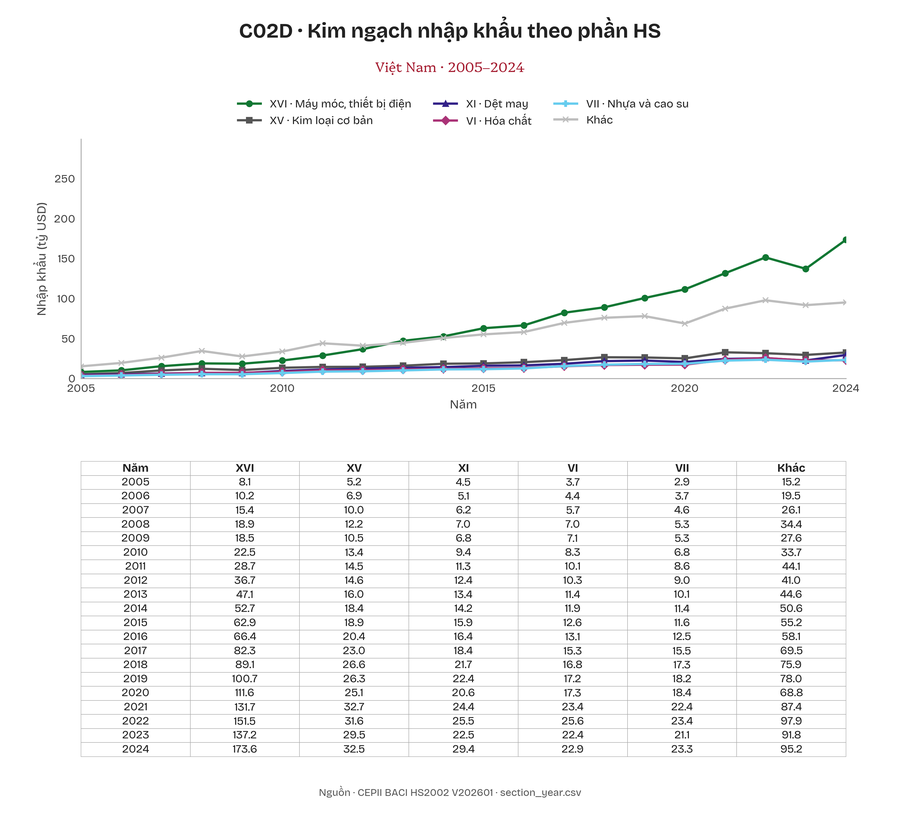

In [12]:
MA_BIEU_DO = "C02D"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, groups, usd = xu_ly_c02d(DU_LIEU)
fig = plot_c02d(data)
assert len(groups) == 6
assert all(sum(column) == data.totals[year, "Import"]
           for year, column in zip(YEARS, zip(*usd, strict=True), strict=True))
kiem_tra_duong(fig.axes[0], tuple(tuple(float(value / 10**9) for value in row) for row in usd))
assert fig.axes[0].get_ylim() == plot_c02c(data).axes[0].get_ylim()
print("Nhóm theo thứ tự:", ", ".join(groups))
print(f"Đã kiểm tra 120 điểm và 20/20 tổng năm từ {format_year(YEARS[0])} đến {format_year(YEARS[-1])}.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02D

Nhập khẩu phần XVI tăng từ **8.1** lên **173.6 tỷ USD** giữa 2005 và 2024. Nhóm Khác đạt **95.2 tỷ USD** năm 2024 theo cách gộp của chiều nhập khẩu.

## C02E · Xuất nhập khẩu của HS84 và HS85

- **Task (Q1.4)** · So sánh kim ngạch xuất khẩu và nhập khẩu của từng chương HS84 và HS85 trong giai đoạn 2005–2024.
- **Dạng** · Biểu đồ đường hai ô (*small multiples line*). Mỗi chương một ô, mỗi ô có hai đường xuất khẩu và nhập khẩu.
- **Lý do** · Hai đường giúp thấy chiều nào có kim ngạch lớn hơn trong từng chương. Dùng chung thang dọc để đối chiếu quy mô và khoảng cách xuất–nhập giữa hai chương.
- **Xử lý** · Lọc `hs2` là chuỗi `"84"` hoặc `"85"`, giữ `Export` và `Import` đủ 20 năm. Chia `trade_usd` cho 1 tỷ để vẽ. Khi đọc chênh lệch, lấy xuất khẩu trừ nhập khẩu trên số gốc rồi mới làm tròn.

**Nguồn** · `data/clean/product_year.csv`, CEPII BACI HS2002 V202601.

In [13]:
def xu_ly_c02e(data_dir):
    """Lấy hai chuỗi XK/NK cho từng chương HS84 và HS85."""
    data = tai_du_lieu(data_dir)
    series = {code: tuple(tuple(float(data.products[year, flow, code] / 10**9)
                                for year in YEARS)
                          for flow in TRADE_FLOW_ORDER)
              for code in CHAPTERS}
    return data, series

In [14]:
def plot_c02e(data):
    """Return the two-panel trade-flow figure for HS84 and HS85."""
    with apply_style():
        fig = Figure(figsize=(11, 12))
        axes = fig.subplots(2, 2, sharey="row", gridspec_kw={"height_ratios": (3, 4.2)})
        fig.subplots_adjust(left=.09, right=.94, bottom=.085, top=.79, hspace=.35, wspace=.2)
        heading(fig, "C02E · Kim ngạch xuất nhập khẩu HS84 và HS85", "2005–2024", "product_year.csv")
        limit = float(max(v for (_, _, code), v in data.products.items() if code in CHAPTERS) / 1_000_000_000) * 1.08
        for code, ax, table in zip(CHAPTERS, *axes):
            ax.set_title(f"HS{code}")
            for flow in TRADE_FLOW_ORDER:
                ax.plot(YEARS, [float(data.products[y, flow, code] / 1_000_000_000) for y in YEARS],
                        color=TRADE_FLOW_COLORS[flow], linestyle=TRADE_FLOW_LINESTYLES[flow],
                        marker=TRADE_FLOW_MARKERS[flow], label=TRADE_FLOW_LABELS[flow])
            value_axis(ax, limit, "Kim ngạch (tỷ USD)" if code == CHAPTERS[0] else "")
            rows = [[format_year(y), *[format_value(data.products[y, flow, code]) for flow in TRADE_FLOW_ORDER]] for y in YEARS]
            add_table(table, ["Năm", *[TRADE_FLOW_LABELS[f] for f in TRADE_FLOW_ORDER]], rows)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, ncols=2, loc="upper center", bbox_to_anchor=(.5, .88))
        return fig

Đã kiểm tra 80 điểm và chung thang dọc cho HS84 và HS85.
Đã lưu: outputs\core_charts\C02\C02E.png và outputs\core_charts\C02\C02E.svg


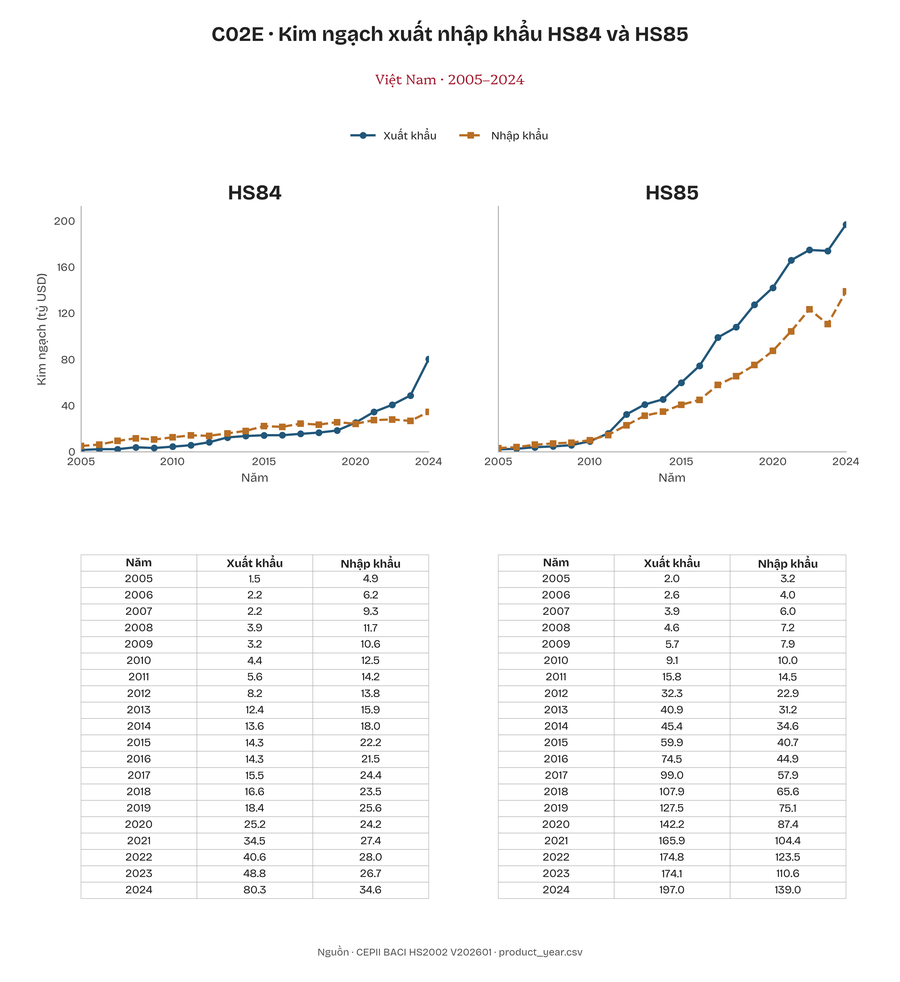

In [15]:
MA_BIEU_DO = "C02E"
DU_LIEU = DATA_DIR
THU_MUC_ANH = OUTPUT_DIR

data, series = xu_ly_c02e(DU_LIEU)
fig = plot_c02e(data)
axes = fig.axes[:2]
for code, ax in zip(CHAPTERS, axes, strict=True):
    assert ax.get_title() == f"HS{code}"
    kiem_tra_duong(ax, series[code])
assert axes[0].get_ylim() == axes[1].get_ylim()
print("Đã kiểm tra 80 điểm và chung thang dọc cho HS84 và HS85.")
png, svg = save_figure(fig, MA_BIEU_DO, THU_MUC_ANH)
print("Đã lưu:", png.relative_to(ROOT), "và", svg.relative_to(ROOT))
display(Image(filename=str(png), width=900))

### Kết luận C02E

Năm 2024, cả hai chương xuất siêu. Chênh lệch xuất khẩu trừ nhập khẩu là **45.8 tỷ USD** ở HS84 và **58.0 tỷ USD** ở HS85.